# Traffic Volume from Quebec - Analysis of permanent sensors data
> To iniate the analysis from this notebook, please download the .xls files using the python file "telecharger_fichier.py" and save it in the same repository as this .ipynb file.  

### This notebook builds on the work of TARCÍSIO COSTA DE SOUZA NETO NETO that was carried out in 2023 as part of his professionnal Master's Degree in Civil Engineering
> Below is the link to his original notebook:
> https://github.com/tarcisiocsn/OpenDataQuebec/blob/main/QuebecTrafficVolumes/count_analysis_new.ipynb

### This notebook is organized in five sections

- #### Section 1: Exploration of the downloaded files and workflow presentation
    - Section 1.1 - Downloaded files exploration
    - Section 1.2 - Worflow presentation
> 
- #### Section 2: Analysis of all data
    - Section 2.1 - Histo data analysis (DJMA, DJME and DJMH)
    - Section 2.2 - Fact84 data analysis (DJMM and average daily flow by day of the week)
    - Section 2.3 - Horaire data analysis (hourly flow)
> 
- #### Section 3: Streamlined analysis of top sections
> 
- #### Section 4: Streamlined analysis by region
> 
- #### Section 5: Streamlined analysis by road category

# Section 1: Exploration of the downloaded files and workflow presentation

## Section 1.1 - Downloaded files exploration

The files are downloaded using the "telecharger_fichier.py" file

In [41]:
%%capture
#MyFunctionsOpenQuebec.py file must be downloaded in the same repository as this .ipynb file

import importlib
import MyFunctionsOpenQuebec

# Force a reload of the module
importlib.reload(MyFunctionsOpenQuebec)

In [43]:
# import packages
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import geopandas as gpd
from MyFunctionsOpenQuebec import count_files, read_count_file, read_filtered_excel, aggregate_filtered_data, custom_mean, count_filtered_data, map_and_add_res_nm_reg
import matplotlib as mpl
mpl.rcParams['figure.max_open_warning'] = 200  # or higher

In [45]:
# Specify the folder path
folder_path = 'debit_circulation_quebec'  
# Get the list of subdirectories
subfolders = next(os.walk(folder_path))[1]

# Print the number of subfolders
print(f"The folder '{folder_path}' contains {len(subfolders)} subfolders.")


The folder 'debit_circulation_quebec' contains 5360 subfolders.


There is one subfolder per route section ('num_sectn_trafc') named as the route section ID. The quantity of subfolders corresponds to the quantity of route sections. 

In [48]:
# Using the count_files function to count the subfolders and the files
aggregated_folder_count, aggregated_file_count = count_files(folder_path, subfolders, prefix=subfolders, separator='_', suffix='.xlsx')
count_folder_count, count_file_count = count_files(folder_path, subfolders, prefix=subfolders, separator='-', suffix='.xlsx')

# Print the counts
print(f"Number of subfolders with aggregated files: {aggregated_folder_count}")
print(f"Total number of aggregated files: {aggregated_file_count}")

print(f"Number of subfolders with count files: {count_folder_count}")
print(f"Total number of count files: {count_file_count}")

Number of subfolders with aggregated files: 680
Total number of aggregated files: 5104
Number of subfolders with count files: 5327
Total number of count files: 14960


In the current notebook, only the aggregated files are used. The count files are used in another notebook for the analysis of total distance travelled. Multiple sections only have count files; only a fraction of the sections have aggregated files. 

In [51]:
# Number of count and aggregated files per year

# Initialize dictionaries to store the counts per year
aggregated_files_per_year = {}
count_files_per_year = {}

# Iterate over subfolders
for subfolder in subfolders:
    # Get the list of files in the subfolder
    files = os.listdir(os.path.join(folder_path, subfolder))
    
    # Iterate over files in the subfolder
    for file in files:
        # Check if it's an aggregated file
        if file.startswith(subfolder) and '_' in file:
            year = file.split('_')[-1].split('.')[0]
            if year in aggregated_files_per_year:
                aggregated_files_per_year[year] += 1
            else:
                aggregated_files_per_year[year] = 1
        # Check if it's a count file
        if file.startswith(subfolder) and '-' in file and 'donnees' in file:
            year = file.split('-')[-2]
            if year in count_files_per_year:
                count_files_per_year[year] += 1
            else:
                count_files_per_year[year] = 1

# Print the counts per year for aggregated files
print("Aggregated Files per Year:")
for year, count in sorted(aggregated_files_per_year.items()):
    print(f"Year {year}: {count}")

# Print the counts per year for count files
print("Count Files per Year:")
for year, count in sorted(count_files_per_year.items()):
    print(f"Year {year}: {count}")


Aggregated Files per Year:
Year 2014: 357
Year 2015: 420
Year 2016: 448
Year 2017: 474
Year 2018: 480
Year 2019: 513
Year 2020: 482
Year 2021: 462
Year 2022: 457
Year 2023: 468
Year 2024: 543
Count Files per Year:
Year 2017: 1
Year 2018: 2354
Year 2019: 2385
Year 2020: 1760
Year 2021: 1947
Year 2022: 1938
Year 2023: 2153
Year 2024: 2422


> A single file can contain information for multiple years. The quantities of files per year presented above and in the graph below do not take that into account; only the year in the title of the file is considered.

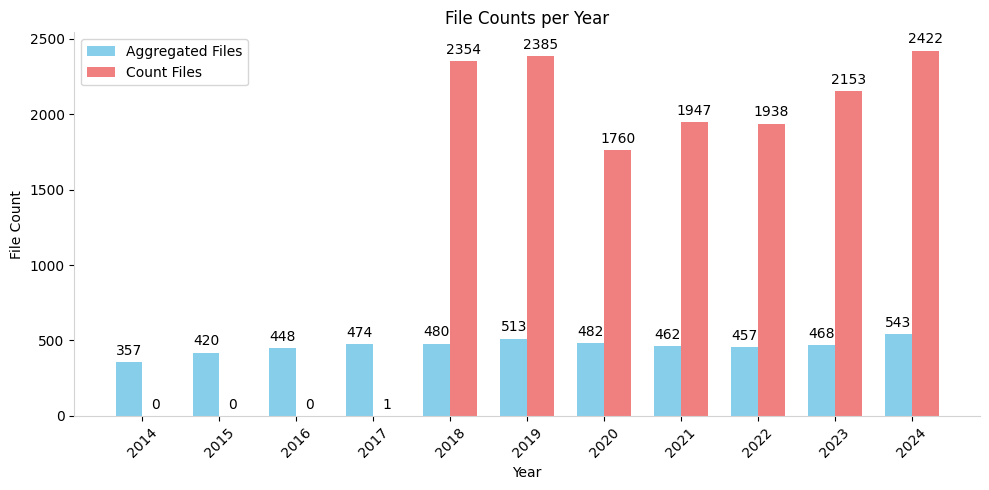

In [54]:
# Extract years and corresponding counts
years = sorted(set(aggregated_files_per_year.keys()) | set(count_files_per_year.keys()))
aggregated_counts = [aggregated_files_per_year.get(year, 0) for year in years]
count_counts = [count_files_per_year.get(year, 0) for year in years]

# Width of the bars
bar_width = 0.35

# Generate the x-axis positions for the bars
x = np.arange(len(years))

# Create the bar plot with a light gray frame and gridlines
fig, ax = plt.subplots(figsize=(10, 5))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('lightgray')
ax.spines['bottom'].set_color('lightgray')

ax.xaxis.set_major_locator(plt.MultipleLocator(1))

aggregated_bars = plt.bar(x - bar_width/2, aggregated_counts, width=bar_width, color='skyblue', label='Aggregated Files')
count_bars = plt.bar(x + bar_width/2, count_counts, width=bar_width, color='lightcoral', label='Count Files')

plt.xlabel('Year')
plt.ylabel('File Count')
plt.title('File Counts per Year')
plt.xticks(x, years, rotation=45)
plt.legend()

# Add text labels for each bar
for bar in aggregated_bars:
    height = bar.get_height()
    plt.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom')

for bar in count_bars:
    height = bar.get_height()
    plt.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom')

plt.tight_layout()
plt.show()

#### Section 1.2 - Presentation of the Workflow
Data analysis begins in section 2.

Different indicators, extracted with the downloaded Excel files, are analyzed. In the files, three sheets are used for analysis:
- The histo sheet contains data about DJMA, DJME and DJMH over the years
- The fact84 sheet is used for analysis of the average daily flow per month and the avererage daily flow by day of the week
- The horaire sheet contains data on average hourly flow.

The analysis is carried out in a similar manner for the different Excel sheets: 

- First, the data by segment from the desired Excel sheet is extracted by direction through the create_complete_df function. A dataframe with total values per segment (including both directions) is then created with the create_total_df function.
- The create_data_dict (or create_histo_dict) function creates a dictionnary containing the total dataframe as well as dataframes of aggregated values per time period. Dataframes for both raw and normalized values are created.  Dataframes are created for values aggregated amongst all available data and data from constant sections (sections with data for all the analyzed years).
- The plot_data (or plot_histo_data) function is used to show the evolution of the aggregated data from the previously created dictionnary. Mean or median dataframes from raw or normalized data can be plotted. The plot can show values for all available data, data from constant sections or show a comparison of both.
- The evolution of the distribution of the data (rather than just the median or the mean) are shown for some indicators.

In section 2, the analysis of all data is carried out step by step. In sections 3, 4 and 5, the analysis carried out in section 2 is streamlined to rapidly show the resulting figures. 

Note: some of the above mentionned functions call functions from the *MyFunctionsOpenQuebec.py* file, created by TARCÍSIO COSTA DE SOUZA NETO NETO.


# Section 2 - Analysis of all data

In [58]:
# Groups of columns by excel sheet. Used later in analysis
subset_dict = {'histo': ['SECTN', 'ANNEE'], 'fact84' : ['SECTN', 'ANNEE', 'MOIS'], 'horaire': ['SECTN', 'ANNEE', 'HRE']}
unchanged_col = {'histo': ['SECTN', 'num_sectn_', 'ANNEE', 'VOIE'], 'fact84' : ['SECTN', 'ANNEE', 'MOIS', 'VOIE'], 'horaire': ['SECTN', 'ANNEE', 'HRE', 'VOIE']}
indicators_dict = {'histo': ['DJMA', 'DJME', 'DJMH'], 'fact84' : ['DIMANCHE', 'LUNDI', 'MARDI', 'MERCREDI', 'JEUDI', 'VENDREDI', 'SAMEDI', 'MOYEN'], 'horaire': ['DIMANCHE', 'SAMEDI', 'OUVRABLE']}
base_indicator_dict = {'histo': 'DJMA_tot', 'fact84' : 'MOYEN_tot', 'horaire': 'OUVRABLE_tot'}
group_by_dict = {'fact84' : ['ANNEE', 'MOIS'], 'horaire': ['ANNEE', 'HRE']}

In [60]:
def create_complete_df (sheet):
    # sheet is the name of the excel sheet the data comes from (string). Possible values are 'histo', 'fact84' and 'horaire'
    # the folder_path and subfolders variables are outside the scope of this function
    data_voie = {}
    
    for voie in [11, 12, 13]:
        data_voie[voie] = aggregate_filtered_data(folder_path, subfolders, 'VOIE', [voie], sheet).drop_duplicates(subset=subset_dict[sheet], keep='first')
        colnames = []
        
        for colname in list (data_voie[voie].columns):
            if colname not in unchanged_col[sheet]:
                colnames.append(colname + '_' + str(voie))
            else:
                colnames.append (colname)
                
        data_voie[voie].columns = colnames
        data_voie[voie] = data_voie[voie].drop(columns = ['VOIE'])

    # Merging the dataframes from different directions
    merged_directions = pd.merge(data_voie[11], data_voie[12], on=subset_dict[sheet], how='outer')
    merged_directions = pd.merge(merged_directions, data_voie[13], on=subset_dict[sheet], how='outer')
    merged_directions = merged_directions.replace({None:np.nan})
    if sheet != 'horaire': # 0s treated differently with horaire data
        merged_directions = merged_directions.replace({0:np.nan})
    else:
        merged_directions = merged_directions[merged_directions['HRE'] != 'Total'] # remove 'total' value in horaire data
    for indicator in indicators_dict[sheet]:
        merged_directions[indicator + '_11_12'] = merged_directions[indicator +'_11'].add(merged_directions[indicator +'_12'], fill_value = 0)

        
    return merged_directions

In [62]:
# Verify the if the indicators per section are equal when calculated as 11 + 12 and when taken directly as 13

def classify_row(col_11_12, col_13):
    
    # This function quantifies the correspondance between (11 + 12) and 13 data for a specific indicator
    # Note: a 0 value is NOT considered a  valid value for the yearly and monthly data ('histo' and 'fact84' sheets), but IS considered a valid value for hourly data ('horaire' sheet)
    
    conditions = [
        (col_11_12.isna())  & (col_13.isna()),
        (col_11_12.isna())  & (col_13.notna()),
        (col_11_12.notna()) & (col_13.isna()),
        (col_11_12.notna()) & (col_11_12 == col_13),
        (col_11_12.notna()) & (col_13.notna()) & (col_11_12 != col_13),
    ]
    return conditions


def verify_lane_equality (merged_directions, sheet):

    # This function prints how the sum of both directions (11 and 12) corresponds to the aggregated data (13) by indicator
    
    categories = {
    0: "No value",
    1: "Only value for 13",
    2: "Only value for 11_12",
    3: "Equal valid values for 11_12 and 13",
    4: "Unequal valid values for 11_12 and 13"
    }

        
    results = {}
    for indicator in indicators_dict[sheet]:
        col_11_12 = merged_directions[indicator+ '_11_12']
        col_13    = merged_directions[indicator + '_13']
        
        conditions = classify_row(col_11_12, col_13) 
        results[indicator] = [cond.sum() for cond in conditions]
        
    for indicator, counts in results.items():
        print(f"############ {indicator} ###############")
        for i, count in enumerate(counts):
            print(f"  {categories[i]}: {count}")
        print()

In [64]:
def create_total_df (merged_directions, sheet):

    # Create dataframe with aggreagated data on both directions on desired indicators
    # The highest value between (11 + 12) and 13 is kept, this decision is arbitrary
    
    indicators_tot = []
    for indicator in indicators_dict[sheet]:
        indicator_tot = indicator + '_tot'
        indicators_tot.append(indicator_tot)
        merged_directions[indicator_tot] = merged_directions[[indicator+'_11_12', indicator+'_13']].max(axis=1) # to keep highest value
        merged_directions['SECTN'] = merged_directions['SECTN'].astype(str)

    keep_cols = subset_dict[sheet] + indicators_tot
    return merged_directions[keep_cols]

In [66]:
def find_max_year(df, sheet):
    
    # Returns latest year suitable for analysis (maximum year in the dataframe or (maximum year -1) if there is not enough data for the maximum year)

    indicator = base_indicator_dict[sheet]
    max_year = max(df['ANNEE'])
    last_year = max_year-1

    mask_max = (df['ANNEE'] == max_year) & (df[indicator].notna())
    mask_last = (df['ANNEE'] == last_year) & (df[indicator].notna())
        
    sections_max = set(df[mask_max]['SECTN'])
    sections_last = set(df[mask_last]['SECTN'])
    
    if len(sections_max) < 0.5*len (sections_last):
        max_year = last_year

    return max_year
    


In [68]:
def constant_sections (df, sheet, max_year = None, year_0 = None, show = True, indicators = None):
    
    # default values for max_year (int), year_0 (int) and indicators (list) can be changed if needed
    # If show is true, the number of constant section per year are printed
    # Function to obtain the list of segements with no null values across specified columns in a time period

    if year_0 is None:
        year_0 = min(df['ANNEE'])
    if max_year is None:
        max_year = find_max_year(df,sheet)
    if indicators is None:
        indicators = [indicator + '_tot' for indicator in indicators_dict[sheet]]
    period_mask = 'MOIS' if sheet == 'fact84' else 'HRE'
    
    if show: 
        print (f"Number of common sections per year with data for every period and every of the following indicators: {indicators} ")
    
    sections = set(df['SECTN'])

    if sheet == 'histo':
        for year in range(max_year, year_0 - 1, -1):
            for indicator in indicators:
                mask = (df['ANNEE'] == year) & (df[indicator].notna()) #!= 0
                sections = sections & set(df[mask]['SECTN'])
            if show:
                print (f"{year} : {len(sections)}")
    else:    
        periods = set(df[period_mask])
        for year in range(max_year, year_0 - 1, -1):
            for period in periods:
                for indicator in indicators:
                    mask = (df['ANNEE'] == year) & (df[period_mask] == period) & (df[indicator].notna())                     
                    sections = sections & set(df[mask]['SECTN'])
            if show:        
                print (f"{year} : {len(sections)}")

    return sections

In [70]:
def find_year_ref (df,sheet, max_year, year_0):
    #the year with data for the most sections is choosen as the reference year
    max_val = 0
    year_ref = 0
    for year in range(max_year, year_0 - 1, -1):
        sections = set(df[(df['ANNEE']==year)&(df[base_indicator_dict[sheet]].notna())]['SECTN'])
        if len(sections)>max_val:
            max_val = len(sections)
            year_ref = year
    return year_ref
    

## Section 2.1 - Histo data analysis (DJMA, DJME and DJMH)

In [73]:
%%capture
histo_data = create_complete_df('histo')

In [74]:
# Saving the dataframe if necessary
histo_data.to_csv("histo_all_data.csv", index = False)

In [75]:
#Reading dataframe if necessary
#histo_data = pd.read_csv("histo_all_data.csv")

In [76]:
verify_lane_equality(histo_data, 'histo')

############ DJMA ###############
  No value: 0
  Only value for 13: 391
  Only value for 11_12: 2151
  Equal valid values for 11_12 and 13: 1686
  Unequal valid values for 11_12 and 13: 2128

############ DJME ###############
  No value: 10
  Only value for 13: 381
  Only value for 11_12: 2151
  Equal valid values for 11_12 and 13: 1458
  Unequal valid values for 11_12 and 13: 2356

############ DJMH ###############
  No value: 10
  Only value for 13: 381
  Only value for 11_12: 2151
  Equal valid values for 11_12 and 13: 1605
  Unequal valid values for 11_12 and 13: 2209



The results above show that total DJMA, DJME and DJMH per segement are inconsistent depending on the method used to obtain them. For the moment, the highest value will be kept.

In [78]:
histo_total = create_total_df(histo_data, 'histo')
histo_total.dtypes

SECTN           str
ANNEE         int64
DJMA_tot    float64
DJME_tot    float64
DJMH_tot    float64
dtype: object

In [79]:
histo_total.to_csv("histo_total_data.csv", index = False)

In [88]:
def create_histo_dict (df, max_year = None, year_0 = None, year_ref = None, show = True):

    #This function is specifically made for data from the histo sheet
    #The years considered for analysis can be defined manually. If they are not, default values are calculated 
    
    if year_0 is None:
        year_0 = min(df['ANNEE'])
    if max_year is None:
        max_year = find_max_year(df,'histo')
    if year_ref is None:
        year_ref = find_year_ref(df,'histo', max_year, year_0)
        
    histo_dict= {'year_ref':year_ref}
    histo_all_dict = {'year_ref':year_ref}
    histo_filtered_years = df[df['ANNEE'].isin(range(year_0, max_year + 1))]
    djma_year_ref = df[df['ANNEE']==year_ref][['SECTN','DJMA_tot']]
    djma_year_ref.columns = ['SECTN', 'DJMA_0']
    histo_merged = pd.merge(histo_filtered_years, djma_year_ref, on  = 'SECTN', how = 'inner')
    djm_tot_list = [djm +'_tot' for djm in indicators_dict['histo']]
    djm_normalized_list = [djm +'_normalized' for djm in indicators_dict['histo']]
    
    for djm, djm_tot, djm_norm in zip(indicators_dict['histo'], djm_tot_list, djm_normalized_list):
        histo_merged[djm_norm] = histo_merged[djm_tot]/histo_merged['DJMA_0']
        histo_dict[djm] = {'constant_sections': constant_sections(df, 'histo', indicators = [djm_tot],max_year = max_year, year_0 = year_0, show = show)}
        histo_dict[djm]['df'] = histo_filtered_years[histo_filtered_years['SECTN'].isin(histo_dict[djm]['constant_sections'])]
        histo_dict[djm]['averages'] = histo_dict[djm]['df'].groupby('ANNEE')[djm + '_tot'].mean()
        histo_dict[djm]['medians'] =  histo_dict[djm]['df'].groupby('ANNEE')[djm + '_tot'].median()

        histo_dict[djm]['df_normalized'] = pd.merge(histo_dict[djm]['df'], djma_year_ref, on  = 'SECTN', how = 'inner')
        histo_dict[djm]['df_normalized'][djm + '_normalized'] = histo_dict[djm]['df_normalized'][djm+'_tot']/histo_dict[djm]['df_normalized']['DJMA_0']
        histo_dict[djm]['averages_normalized'] = histo_dict[djm]['df_normalized'].groupby('ANNEE')[djm + '_normalized'].mean()
        histo_dict[djm]['medians_normalized'] =  histo_dict[djm]['df_normalized'].groupby('ANNEE')[djm + '_normalized'].median()
    
    histo_all_dict['averages'] = histo_merged.groupby('ANNEE')[djm_tot_list].mean()
    histo_all_dict['medians'] = histo_merged.groupby('ANNEE')[djm_tot_list].median()
    histo_all_dict['averages_normalized'] = histo_merged.groupby('ANNEE')[djm_normalized_list].mean()
    histo_all_dict['medians_normalized'] = histo_merged.groupby('ANNEE')[djm_normalized_list].median()
    histo_all_dict ['histo_merged'] = histo_merged

    return histo_dict, histo_all_dict


In [90]:
histo_dict, histo_all_dict = create_histo_dict(histo_total)

Number of common sections per year with data for every period and every of the following indicators: ['DJMA_tot'] 
2024 : 543
2023 : 509
2022 : 458
2021 : 410
2020 : 384
2019 : 372
2018 : 361
2017 : 343
2016 : 323
2015 : 305
2014 : 280
2013 : 258
2012 : 231
2011 : 199
Number of common sections per year with data for every period and every of the following indicators: ['DJME_tot'] 
2024 : 543
2023 : 509
2022 : 458
2021 : 405
2020 : 380
2019 : 369
2018 : 359
2017 : 341
2016 : 321
2015 : 303
2014 : 278
2013 : 256
2012 : 229
2011 : 197
Number of common sections per year with data for every period and every of the following indicators: ['DJMH_tot'] 
2024 : 543
2023 : 509
2022 : 458
2021 : 405
2020 : 380
2019 : 369
2018 : 359
2017 : 341
2016 : 321
2015 : 303
2014 : 278
2013 : 256
2012 : 229
2011 : 197


In [96]:
# Look for potential outliers, for the moment, the potential outilers are considered in subsequent analysis
for djm in indicators_dict['histo']:
    print(histo_dict[djm]['df_normalized'][djm + '_normalized'].describe())

count    2786.000000
mean        0.954665
std         0.186996
min         0.361775
25%         0.881356
50%         0.949431
75%         1.000000
max         3.785714
Name: DJMA_normalized, dtype: float64
count    2758.000000
mean        1.080232
std         0.228520
min         0.266212
25%         0.981481
50%         1.050000
75%         1.142857
max         4.500000
Name: DJME_normalized, dtype: float64
count    2758.000000
mean        0.848447
std         0.183477
min         0.346296
25%         0.761905
50%         0.840909
75%         0.914015
max         3.428571
Name: DJMH_normalized, dtype: float64


In [233]:
def plot_histo_data (histo_dict  = None, histo_all_dict = None, stat = 'averages', normalized = True, title_begin = ''):

    # This function gives different possibilities for plotting histo data
    # stat can either be 'average' or 'median'
    # histo_dict contains aggregated values from constant sections while histo_all_dict contains aggregated values from all available data.
    # It is possible to plot only data from either or thos dictionnaries (if one of them is defined) or from both (if they are bboth defined)
    stat = stat + 's'
    djm_list = indicators_dict['histo']
    if normalized:
        stat = stat+'_normalized'
        djm_list_all = [djm+'_normalized' for djm in djm_list]
    else:
        djm_list_all = [djm+'_tot' for djm in djm_list]
            
    sns.set(style='whitegrid')

    # Create a new figure and axis objects for the line plot
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ['#4C72B0', '#55A868',  '#C44E52']
    # Plot the trend lines
    for color, djm, djm_all in zip(colors, djm_list, djm_list_all):
        if histo_dict is not None:
            histo_dict[djm][stat].plot(ax=ax, color=color, linewidth=1, marker='o', markersize=2, label= f'{djm} constant sections (n={len(histo_dict[djm]['constant_sections'])})')
            year_ref = histo_dict['year_ref']
        
        if histo_all_dict is not None:
            df = histo_all_dict['histo_merged']
            sections = set(df[(df['ANNEE']==year_ref)&(df[base_indicator_dict['histo']].notna())]['SECTN'])
            histo_all_dict[stat][djm_all].plot(ax=ax, color=color, linewidth=1, linestyle='dashed', marker='o', markersize=2, label=f'{djm} all sections (n <= {len(sections)})')
            year_ref = histo_all_dict['year_ref']
            
    # Set the title and axis labels for the line plot
    ax.set_title(title_begin, fontsize=12)
    ax.set_xlabel('Year', fontsize=12)
    
    if normalized:
        ax.set_ylabel(f"{stat} (base year: {year_ref})", fontsize=12)
        ax.set_ylim(0, 2)
        #if normalized is True, the 'all sections' data contains only data for sections that had a DJMA in the reference year
    else:
        ax.set_ylabel(stat, fontsize=12)
        ax.set_ylim(0, 60000)
    
    # Customize tick labels for the line plot
    ax.tick_params(axis='x', labelrotation=0, labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    
    # Remove the top and right spines for the line plot
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Show the legend for the line plot
    ax.legend()
    
    # Show the plots
    plt.tight_layout()
    plt.show()


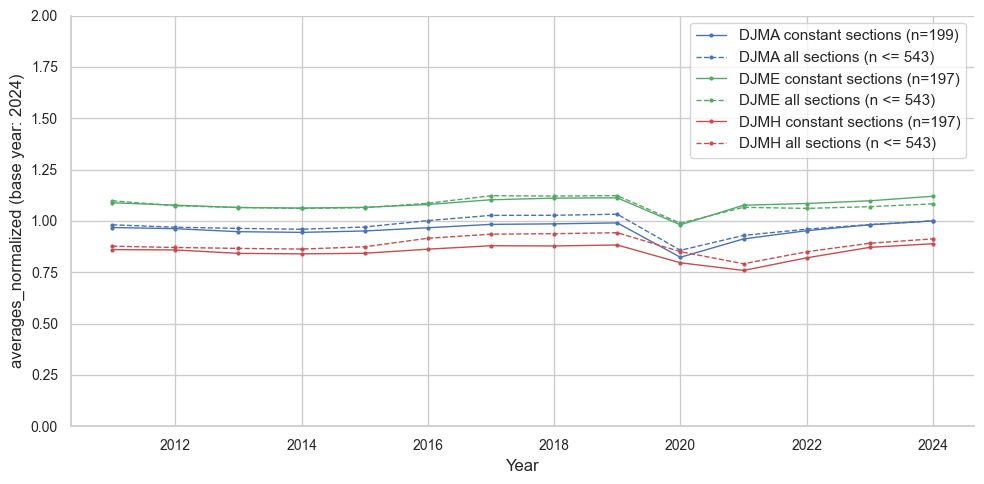

In [237]:
plot_histo_data (histo_dict  = histo_dict, histo_all_dict = histo_all_dict, stat = 'average', normalized = True)

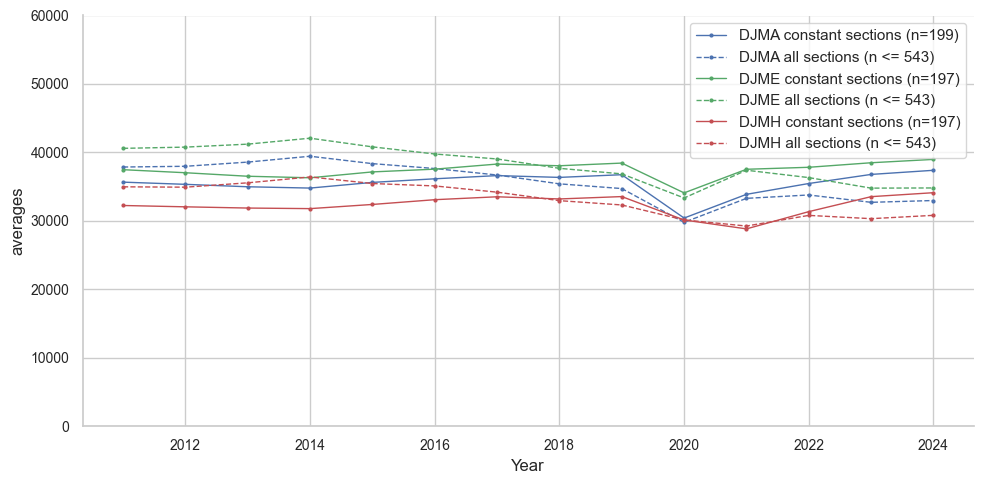

In [239]:
plot_histo_data (histo_dict  = histo_dict, histo_all_dict = histo_all_dict, stat = 'average', normalized = False)

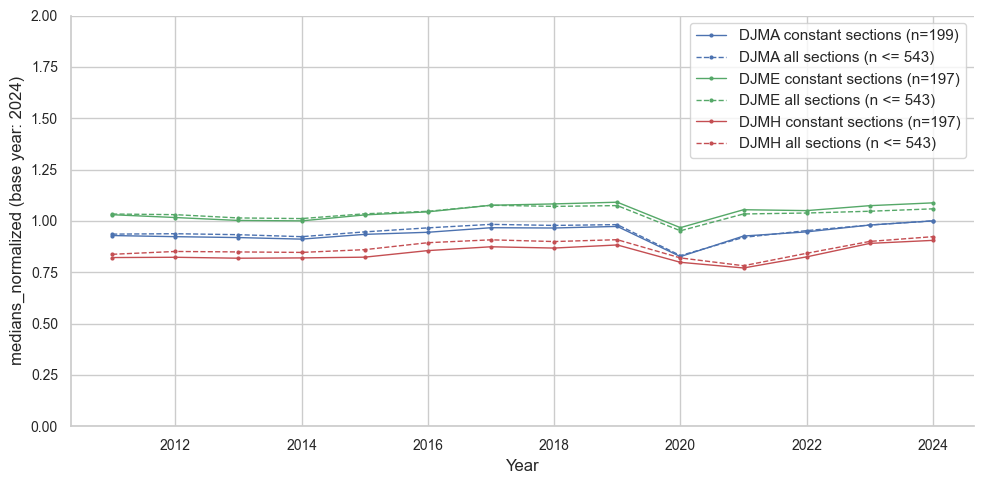

In [241]:
plot_histo_data (histo_dict  = histo_dict, histo_all_dict = histo_all_dict, stat = 'median', normalized = True)

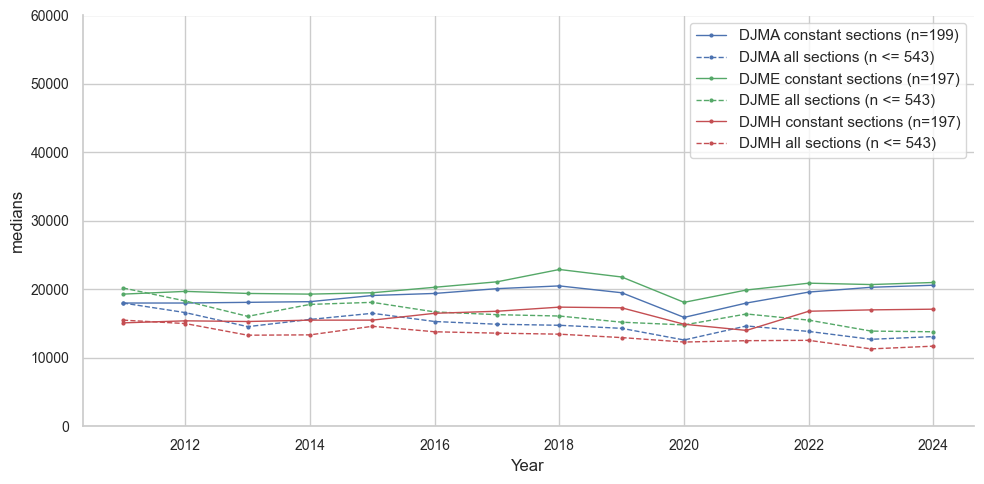

In [243]:
plot_histo_data (histo_dict  = histo_dict, histo_all_dict = histo_all_dict, stat = 'median', normalized = False)

The figure above shows that the trends are not the same if we only consider the sections with data for all the analyzed years. ** not shown, but the trends look different if the sum of 11 and 12 directions is used rather that the highest value between 11+12 and 13. This could be further analyzed

In [109]:
def plot_histo_distribution(histo_dict, constant_sections = True, normalized = True, inner_percentile = 25, outer_percentile = 10):

    if normalized:
        suffix = '_normalized'
        df_name = 'df_normalized'
    else:
        suffix = '_tot'
        df_name = 'df'

    year_ref = histo_dict['year_ref']
    
    if constant_sections:
        years = sorted(set(histo_dict['DJMA'][df_name]['ANNEE']))
    else:
        years = sorted(set(histo_dict['histo_merged']['ANNEE']))
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True, sharey = True)
    
    for ax, djm in zip(axes, indicators_dict['histo']):
        mean_vals   = []
        median_vals = []
        lower_x, upper_x = [], []  # inner zone
        lower_z, upper_z = [], []  # outer zone
        
        if constant_sections:
            nb_sectn = '= ' + str(len(set(histo_dict[djm][df_name]['SECTN'])))
        else:
            df = histo_dict['histo_merged']
            nb_sectn = '<= ' + str(len(set(df[(df['ANNEE'] == year_ref)&(df[base_indicator_dict['histo']].notna())]['SECTN'])))
    
        for year in years:
            if constant_sections:
                df = histo_dict[djm][df_name]
                data = df[df['ANNEE']== year][djm+suffix]
                
            else:
                df = histo_dict['histo_merged']
                data = df[df['ANNEE']==year][djm+suffix]
                
            mean_vals.append(data.mean())
            median_vals.append(data.median())
            lower_x.append(np.nanpercentile(data, 100 - inner_percentile))
            upper_x.append(np.nanpercentile(data, inner_percentile))
            lower_z.append(np.nanpercentile(data, 100 - outer_percentile))
            upper_z.append(np.nanpercentile(data, outer_percentile))
    
        # Shaded zones
        ax.fill_between(years, lower_z, upper_z, alpha=0.2, color='steelblue', label=f'{outer_percentile}th - {100 - outer_percentile}th percentile zone')
        ax.fill_between(years, lower_x, upper_x, alpha=0.4, color='steelblue', label=f'{inner_percentile}th - {100 - inner_percentile}th percentile zone')
    
        # Lines
        ax.plot(years, mean_vals,   color='steelblue', linewidth=2,               label='Mean')
        ax.plot(years, median_vals, color='steelblue', linewidth=2, linestyle='--', label='Median')

        if normalized:
            ax.set_ylabel(f"{djm} / DJMA_{year_ref} (n {nb_sectn})", fontsize=12)
        else:
            ax.set_ylabel(f"{djm} (n {nb_sectn})", fontsize=12)
        ax.legend(loc='upper left')
        ax.grid(True, alpha=0.3)
        ax.set_xticks(years)
        ax.set_xticklabels(years, rotation=45)
    
    axes[-1].set_xlabel('Year', fontsize=12)
    #fig.suptitle('Evolution of normalized DJMA, DJME and DJMH distributions on constant sections over time', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

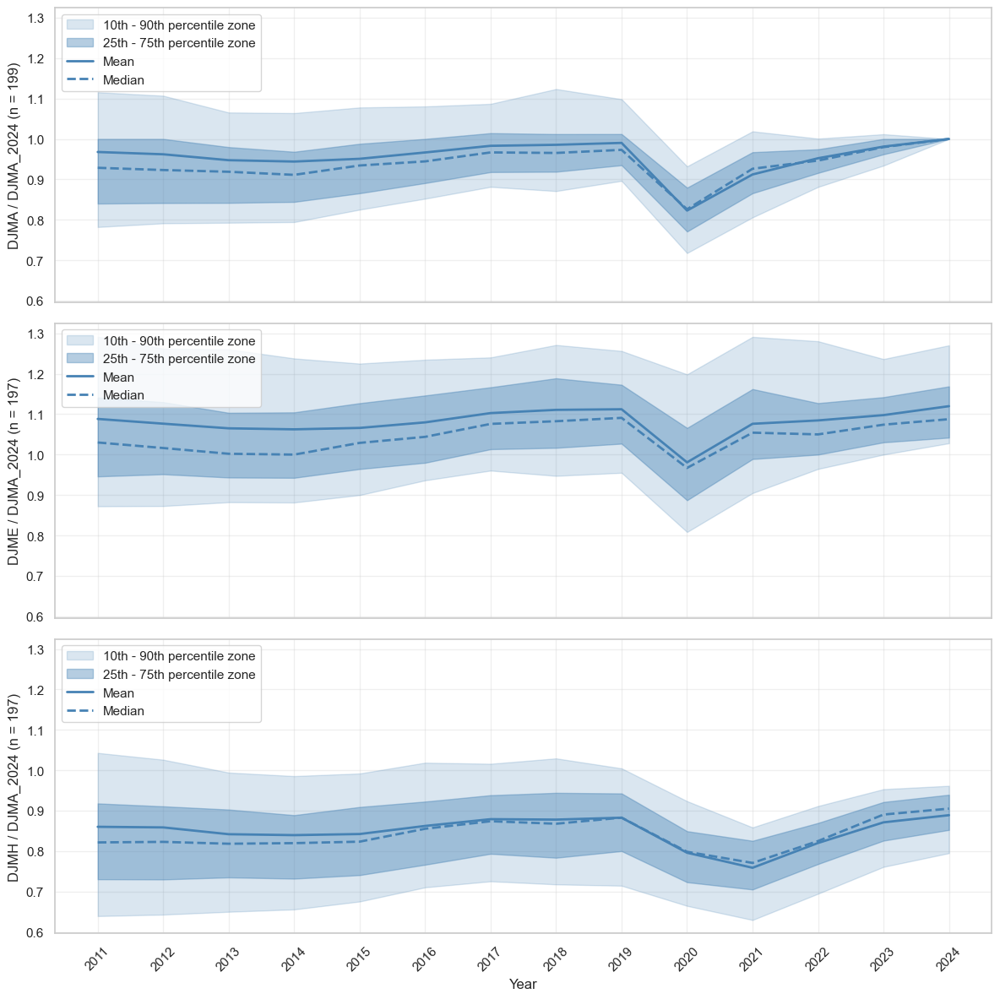

In [111]:
plot_histo_distribution(histo_dict)

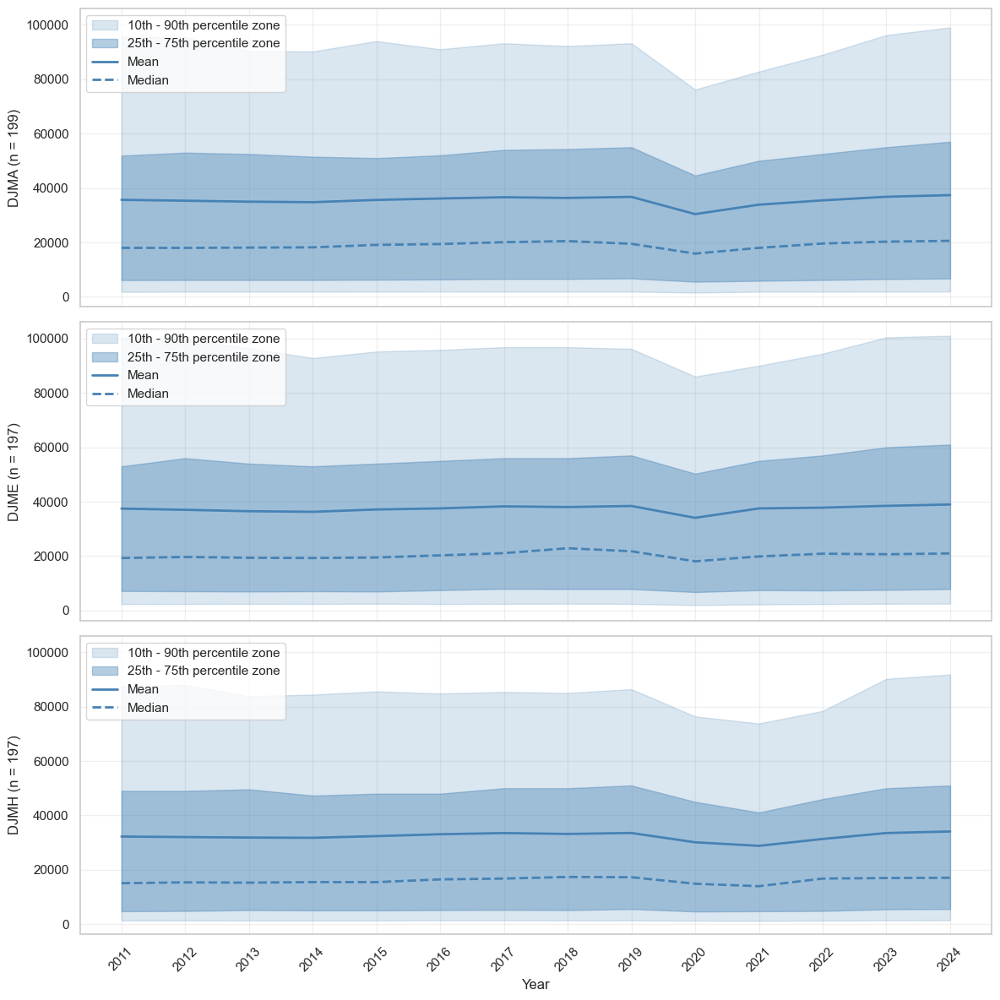

In [113]:
plot_histo_distribution(histo_dict, normalized = False)

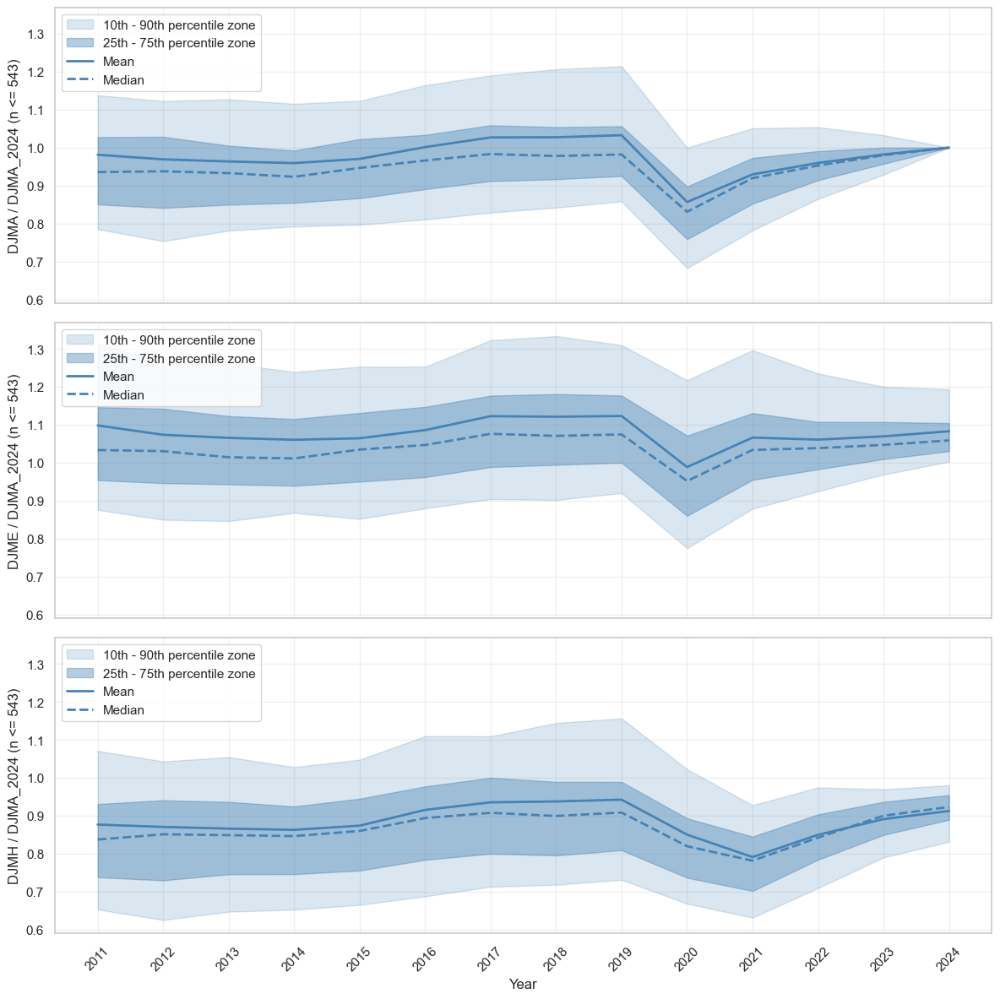

In [115]:
plot_histo_distribution(histo_all_dict, constant_sections = False)

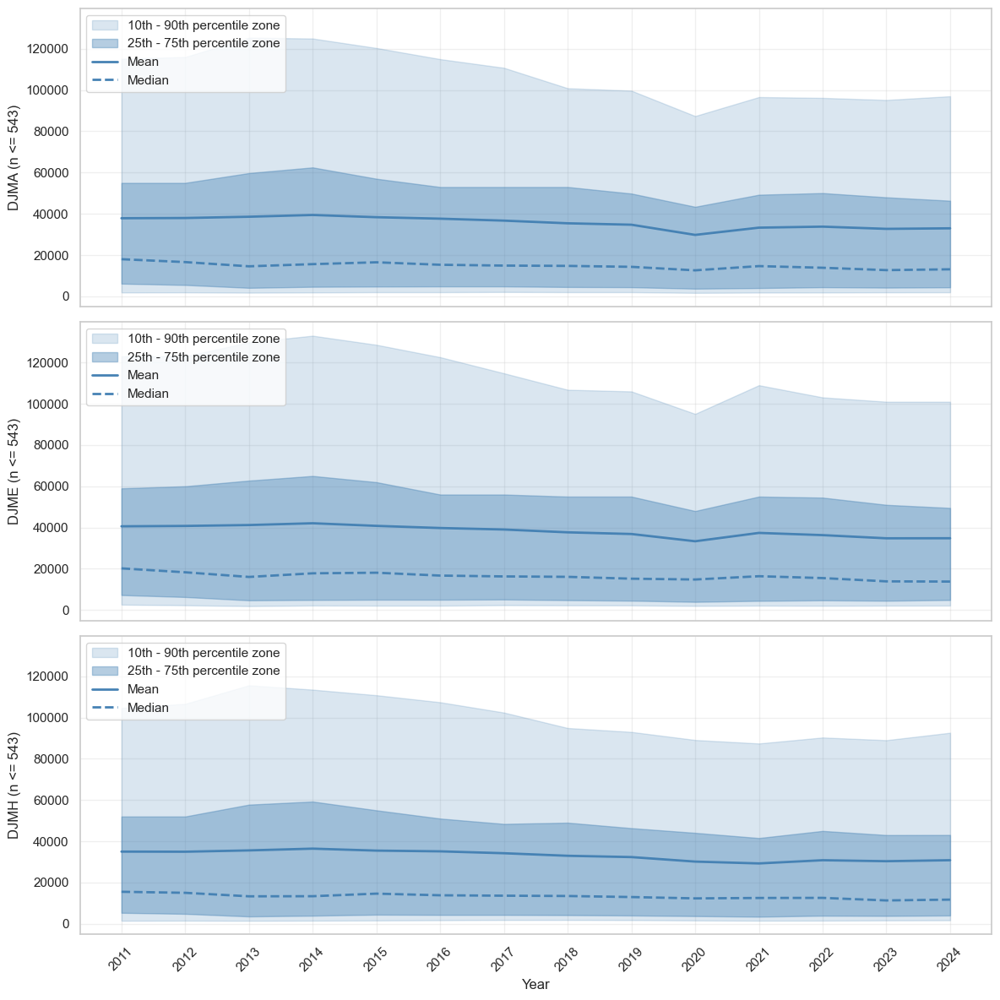

In [117]:
plot_histo_distribution(histo_all_dict, constant_sections = False, normalized = False)

## Section 2.2 - Fact84 data analysis (DJMM and average daily flow by day of the week)

In [119]:
%%capture
fact84_df = create_complete_df ('fact84')

In [120]:
verify_lane_equality (fact84_df, 'fact84')

############ DIMANCHE ###############
  No value: 0
  Only value for 13: 0
  Only value for 11_12: 27900
  Equal valid values for 11_12 and 13: 19682
  Unequal valid values for 11_12 and 13: 13642

############ LUNDI ###############
  No value: 0
  Only value for 13: 0
  Only value for 11_12: 27900
  Equal valid values for 11_12 and 13: 20233
  Unequal valid values for 11_12 and 13: 13091

############ MARDI ###############
  No value: 0
  Only value for 13: 0
  Only value for 11_12: 27900
  Equal valid values for 11_12 and 13: 20237
  Unequal valid values for 11_12 and 13: 13087

############ MERCREDI ###############
  No value: 0
  Only value for 13: 0
  Only value for 11_12: 27900
  Equal valid values for 11_12 and 13: 20329
  Unequal valid values for 11_12 and 13: 12995

############ JEUDI ###############
  No value: 0
  Only value for 13: 0
  Only value for 11_12: 27900
  Equal valid values for 11_12 and 13: 20576
  Unequal valid values for 11_12 and 13: 12748

############ VENDRE

In [123]:
fact84_total = create_total_df (fact84_df, 'fact84')
fact84_total.head()

,SECTN,ANNEE,MOIS,DIMANCHE_tot,LUNDI_tot,MARDI_tot,MERCREDI_tot,JEUDI_tot,VENDREDI_tot,SAMEDI_tot,MOYEN_tot
0,1012500,2014,Août,86140,85690,85350,87370,88490,98630,87650,89000
1,1012500,2014,Avril,71060,73950,73980,76440,80950,88560,77940,78000
2,1012500,2014,Décembre,65850,73940,74210,76000,79160,83430,70060,75000
3,1012500,2014,Février,65500,70280,70920,71890,78030,82640,70380,73000
4,1012500,2014,Janvier,61040,67770,67300,69680,74720,83260,68740,70000


In [125]:
def add_mean_by_weekday(df):
    ind_list = [ind + '_tot' for ind in indicators_dict['fact84']]
    means_df = df.groupby(['SECTN','ANNEE'], as_index = False)[ind_list].mean()
    means_df['MOIS'] = 'TOUS'

    return pd.concat([df,means_df])

In [127]:
fact84_total = add_mean_by_weekday(fact84_total)

In [227]:
def create_data_dict (df, sheet, df_djma, max_year = None, year_0 = None, year_ref = None, show = True):

    # This function is used both for fact84 data and horaire data
    # The df is the 'total' dataframe, values per section taking into account flow in both directions
    # The df_djma is used to normalize the data with the DJMA of the corresponding section in the reference year

    if year_0 is None:
        year_0 = min(df['ANNEE'])
    if max_year is None:
        max_year = find_max_year(df,sheet)
    if year_ref is None:
        year_ref = find_year_ref(df,sheet, max_year, year_0)

    data_dict = {'year_ref':year_ref}
    df = df.drop(columns=['DJMA_0'], errors='ignore') #necessary from streamlined analysis (sections 3-4-5)
    df_filtered_year = df[df['ANNEE'].isin(range(year_0, max_year + 1))]
    djma_year_ref = df_djma[df_djma['ANNEE']==year_ref][['SECTN','DJMA_tot']]
    djma_year_ref.columns = ['SECTN', 'DJMA_0']
    df_merged = pd.merge(df_filtered_year, djma_year_ref, on  = 'SECTN', how = 'left')

    list_ind_tot = []
    list_ind_normalized = []
    
    for indicator in indicators_dict[sheet]:
        ind_tot = indicator+'_tot'
        ind_normalized = indicator+'_normalized'
        list_ind_tot.append(ind_tot)
        list_ind_normalized.append (ind_normalized)
        df_merged[ind_normalized] = df_merged[ind_tot]/df_merged['DJMA_0']

    constant_sect = constant_sections(df_merged, sheet, max_year = max_year, year_0 = year_0,  show = show)
    df_constant = df_merged[df_merged['SECTN'].isin(constant_sect)]
    data_dict['all'] = {'df': df_merged}
    data_dict['constant'] = {'df': df_constant}
    for name in ['all', 'constant']:
        for suffix, list_indicators in [('_tot', list_ind_tot), ('_normalized', list_ind_normalized)]:
            data_dict[name]['averages' + suffix] =  data_dict[name]['df'].groupby(group_by_dict[sheet], as_index = False)[list_indicators].mean()
            data_dict[name]['medians' + suffix] =  data_dict[name]['df'].groupby(group_by_dict[sheet], as_index = False)[list_indicators].median()

    return data_dict

In [229]:
fact84_dict = create_data_dict(fact84_total, 'fact84',  histo_all_dict ['histo_merged'])

Number of common sections per year with data for every period and every of the following indicators: ['DIMANCHE_tot', 'LUNDI_tot', 'MARDI_tot', 'MERCREDI_tot', 'JEUDI_tot', 'VENDREDI_tot', 'SAMEDI_tot', 'MOYEN_tot'] 
2024 : 543
2023 : 447
2022 : 421
2021 : 361
2020 : 340
2019 : 323
2018 : 290
2017 : 269
2016 : 254
2015 : 233
2014 : 200


In [133]:
month_order = ['Janvier', 'Février', 'Mars', 'Avril', 'Mai', 'Juin', 'Juillet', 'Août', 'Septembre', 'Octobre', 'Novembre', 'Décembre']
hour_order = ['0-1', '1-2', '2-3', '3-4', '4-5', '5-6', '6-7', '7-8', '8-9', '9-10', '10-11', '11-12', '12-13', '13-14', '14-15', '15-16', '16-17', '17-18', '18-19', '19-20', '20-21', '21-22', '22-23', '23-24'] 
day_order = ['DIMANCHE', 'LUNDI', 'MARDI', 'MERCREDI', 'JEUDI', 'VENDREDI', 'SAMEDI', 'MOYEN']
order_dict = {'fact84': month_order, 'horaire': hour_order, 'weekday' : day_order}
order_var = {'fact84': 'MOIS', 'horaire': 'HRE'}
agg_period_dict = indicators_dict
agg_period_dict['weekday'] = month_order + ['TOUS']
subplot_dict = {'fact84': {'n_rows' : 3, 'n_cols' : 3, 'width' : 20, 'height' : 24, 'ax_legend' : 8, 'ax_empty': [8], 'y_label': 'Daily Flow', 'title': 'DJMM'}, 
'horaire': {'n_rows' : 2, 'n_cols': 3, 'width' : 18, 'height' : 12, 'ax_legend' : 3, 'ax_empty': [3,4,5], 'y_label': 'Hourly Flow', 'title': 'Mean Hourly Flow'}, 
'weekday': {'n_rows' : 5, 'n_cols': 3, 'width' : 18, 'height' : 30, 'ax_legend' : 13, 'ax_empty': [13, 14], 'y_label': 'Daily Flow', 'title': 'Mean Daily Flow by weekday'}}
y_axis_dict = {}

In [135]:
def plot_data(data_dict, sheet, stat = 'average', base_data = 'both', suffix = 'normalized', weekday = False, title_begin = ''):
    
    #base_data can be 'constant' or 'all' or 'both', suffix can be 'normalized' or 'tot', stat can be 'average' or 'median'
    # sheet can be 'fact84' or 'horaire'
    # the analysis is a bit different for weekdays
    
    list_base = ['all', 'constant'] if base_data == 'both' else [base_data]
        
    option = 'weekday' if weekday else sheet
    df_name = stat + 's_' + suffix
    colname = order_var[sheet]

    fig, axes = plt.subplots(subplot_dict[option]['n_rows'], subplot_dict[option]['n_cols'], figsize=(subplot_dict[option]['width'], subplot_dict[option]['height']), sharex=True, sharey=True)
    axes = axes.flatten()
    title_fontsize  = 20
    label_fontsize  = 12 if sheet == 'horaire' else 16
    legend_fontsize = 16

    base_ordered_dict = {}
    for base in list_base:
        data = data_dict[base][df_name]
        new_names = [colname.split('_')[0] for colname in list(data.columns)]
        data.columns = new_names
        if option == 'fact84':
            data = data[data['MOIS']!= 'TOUS']
        if weekday:
            list_col = ['ANNEE', 'MOIS'] + day_order[:-1]
            data = data[list_col]
            data[colname] = pd.Categorical(data[colname], categories=order_dict[sheet]+['TOUS'], ordered=True)
        else:
            data[colname] = pd.Categorical(data[colname], categories=order_dict[sheet], ordered=True)
        
        data = data.sort_values(['ANNEE', colname])
        base_ordered_dict[base] = data

    year_ref = data_dict['year_ref']
    text_normalized = f'(normalized by the DJMA of the reference year - {year_ref})' if suffix == 'normalized' else ''
    base_text = ''
    for i,base in enumerate(list_base):
        df = data_dict[base]['df']
        n = len(df[df['ANNEE'] == year_ref]['SECTN'].unique())
        n_text = f"(n = {n})" if base == 'constant' else f"(n <= {n})"
        and_text = ' and for ' if (base_data == 'both') &(i ==0) else ''
        base_text = base_text + base + ' sections ' + n_text + and_text
        
    title = f"{title_begin}{stat} of {subplot_dict[option]['title']} {text_normalized} by year for {base_text}"
    
    data_temp = list(base_ordered_dict.values())[0]
    years = sorted(data_temp['ANNEE'].unique())
    colors = plt.cm.tab20.colors[:len(years)] # different colors for 20 years at a time 

    for i, agg_period in enumerate(agg_period_dict[option]):
        ax = axes[i]
        xticklabels = day_order[:-1] if weekday else order_dict[sheet]
        for year, color in zip(years, colors):
            for name, data in base_ordered_dict.items():
                linestyle = '-' if name == 'constant' else '--'
                if weekday:
                    values = data[(data['ANNEE'] == year)& (data['MOIS'] == agg_period)][day_order[:-1]].values.flatten()
                    ax.plot(xticklabels, values, color = color, linewidth=1, linestyle = linestyle, label=str(year))
                    
                else:
                    values = data[data['ANNEE'] == year][agg_period].values.flatten()
                    ax.plot(xticklabels, values, color = color, linewidth=1, linestyle = linestyle, label=str(year))
            
        ax.set_title(agg_period, fontsize=title_fontsize)
        y_label = 'Normalized ' + subplot_dict[option]['y_label'] if suffix == 'normalized' else subplot_dict[option]['y_label']
        if i%subplot_dict[option]['n_cols'] ==0 :
            ax.set_ylabel(y_label, fontsize=label_fontsize)
            
        if (i/subplot_dict[option]['n_cols'] >= subplot_dict[option]['n_rows'] - 1) or (sheet == 'horaire'):
            ax.set_xticks(range(len(xticklabels)))
            ax.set_xticklabels(xticklabels, rotation=45, ha='right', fontsize=label_fontsize)
            ax.tick_params(labelbottom=True)

    #Clear unused subplots
    for index in subplot_dict[option]['ax_empty']:
        axes[index].axis('off')
    # Build legend in an empty subplot ()
    ax_legend = axes[subplot_dict[option]['ax_legend']]
    
    # Line style entries
    legend_handles = []
    
    if base_data == 'both':
        legend_handles = [
            plt.Line2D([0], [0], color='black', linestyle='-',  label=f'constant sections'), 
            plt.Line2D([0], [0], color='black', linestyle='--', label='all sections'),
        ]
    # One colored entry per year
    for year, color in zip(years, colors):
        legend_handles.append(plt.Line2D([0], [0], color=color, linestyle='-', linewidth=2, label=str(year)))
    
    ax_legend.legend(handles=legend_handles, fontsize=legend_fontsize, loc='center', title='Legend', title_fontsize=legend_fontsize)
    fig.suptitle(title, fontsize=20, y=1.01)


    fig.tight_layout()
    plt.show()
    

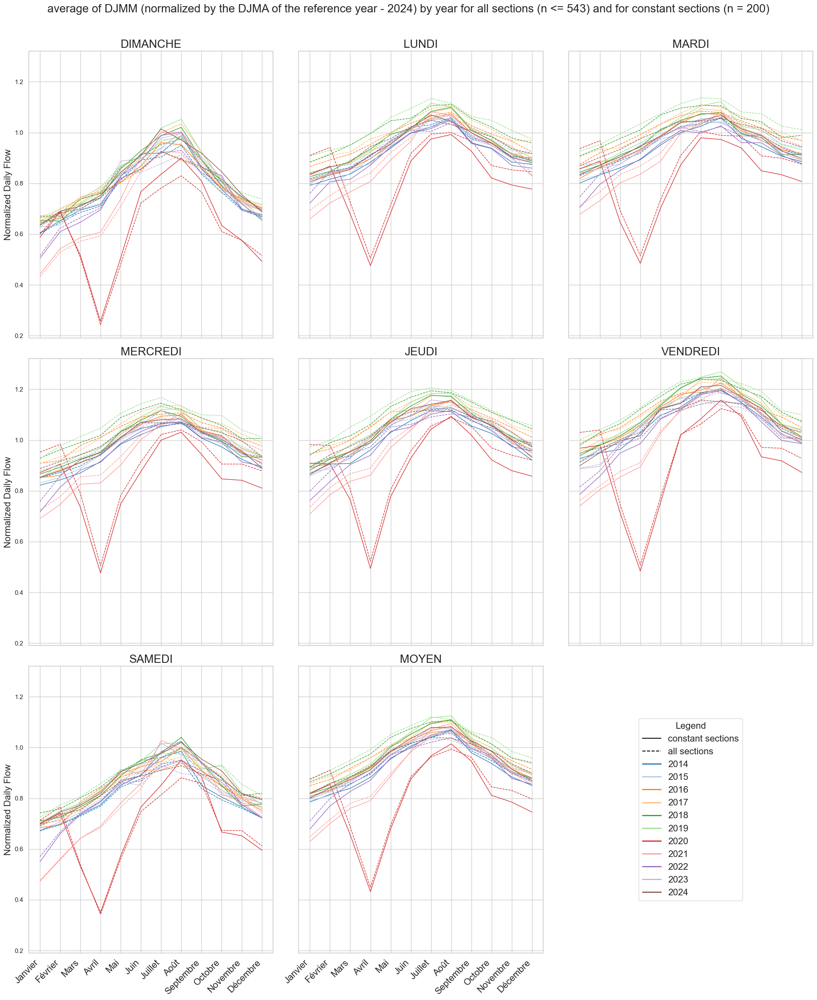

In [137]:
plot_data(fact84_dict, 'fact84')

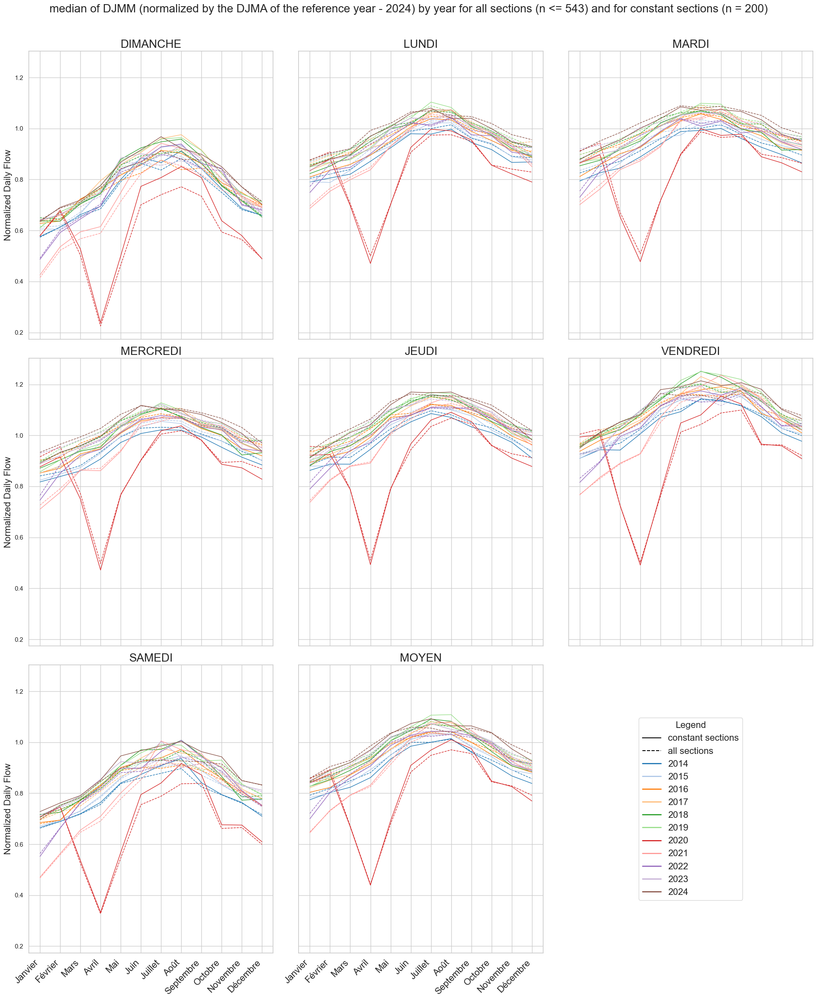

In [139]:
plot_data(fact84_dict, 'fact84', stat = 'median')

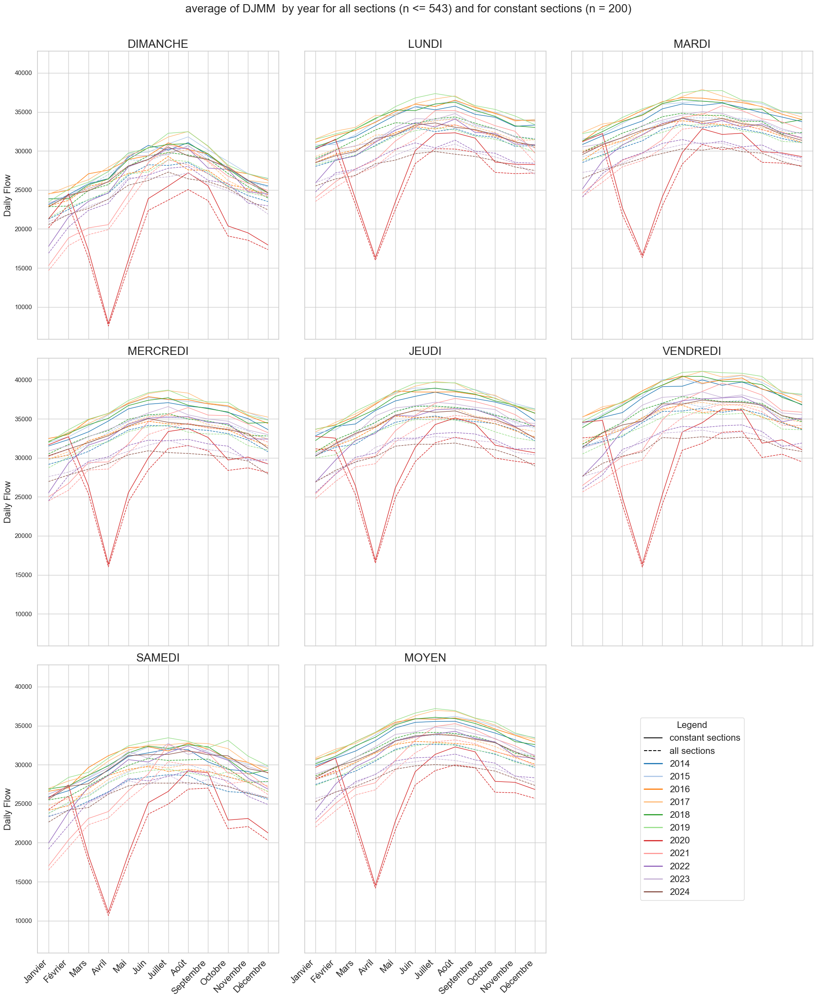

In [141]:
plot_data(fact84_dict, 'fact84', suffix = 'tot')

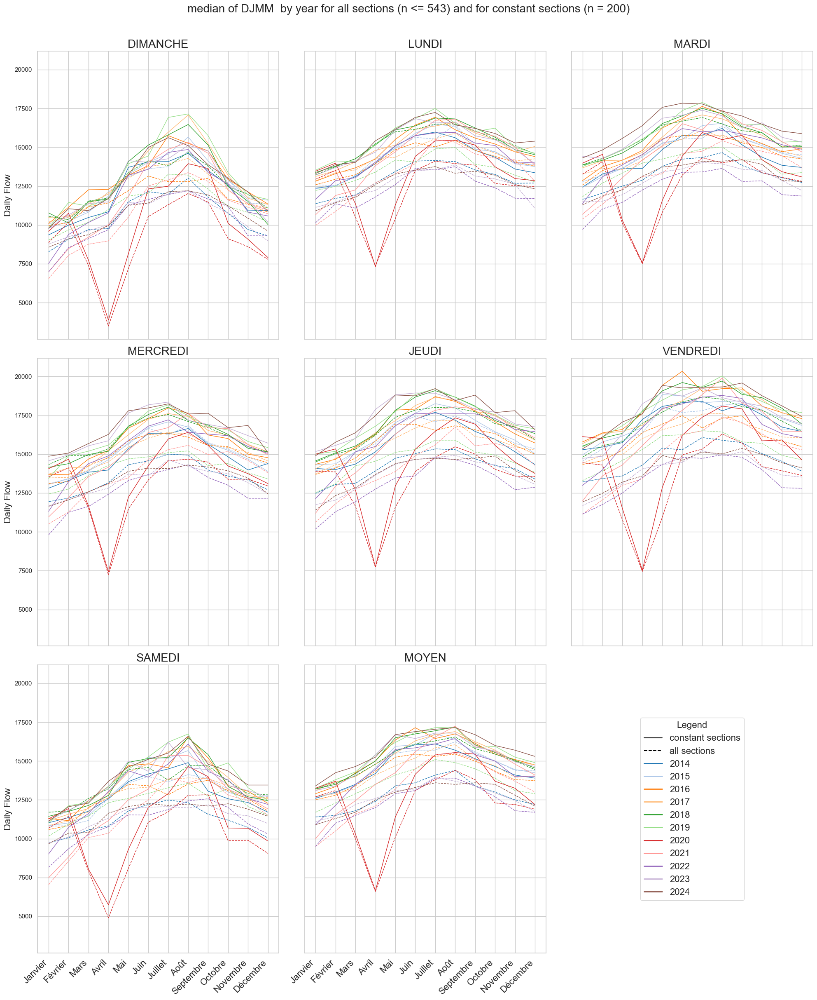

In [143]:
plot_data(fact84_dict, 'fact84', stat = 'median', suffix = 'tot')

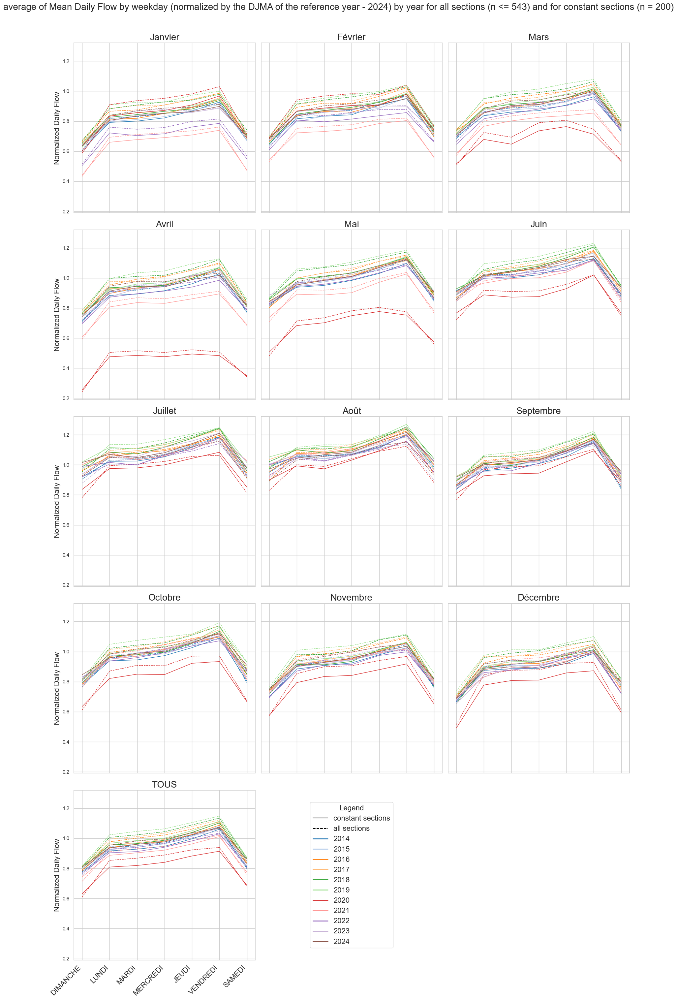

In [145]:
plot_data(fact84_dict, 'fact84', weekday = True)

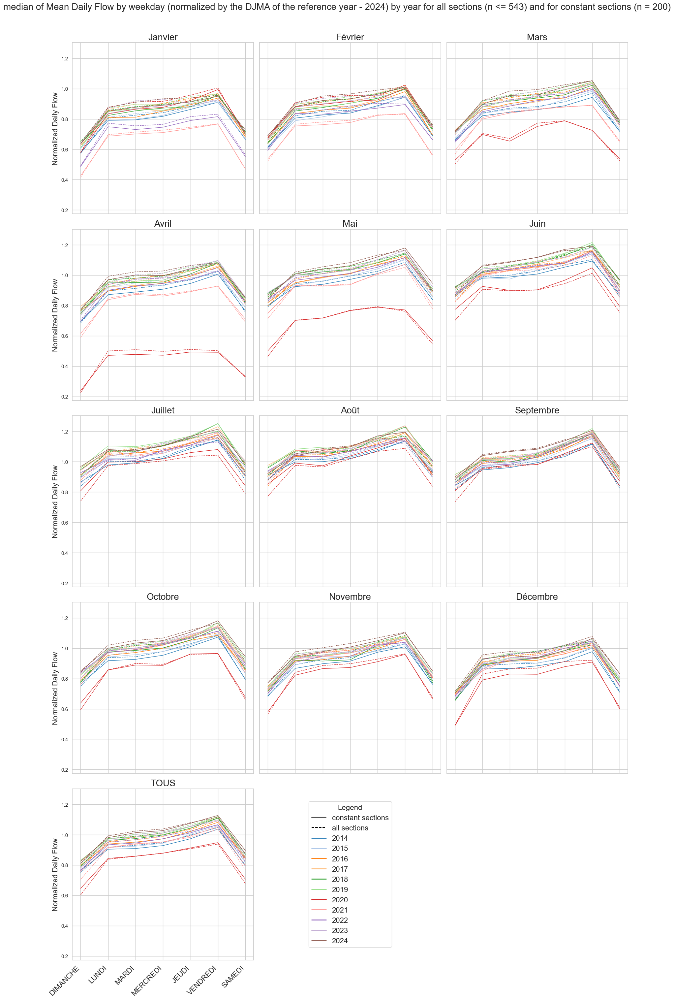

In [147]:
plot_data(fact84_dict, 'fact84', weekday = True, stat = 'median')

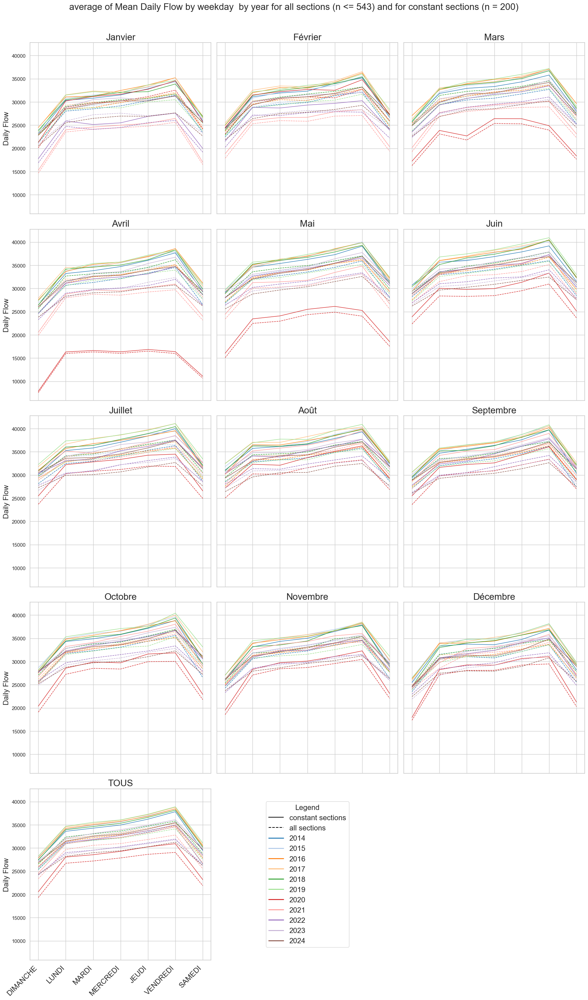

In [149]:
plot_data(fact84_dict, 'fact84', weekday = True, suffix = 'tot')

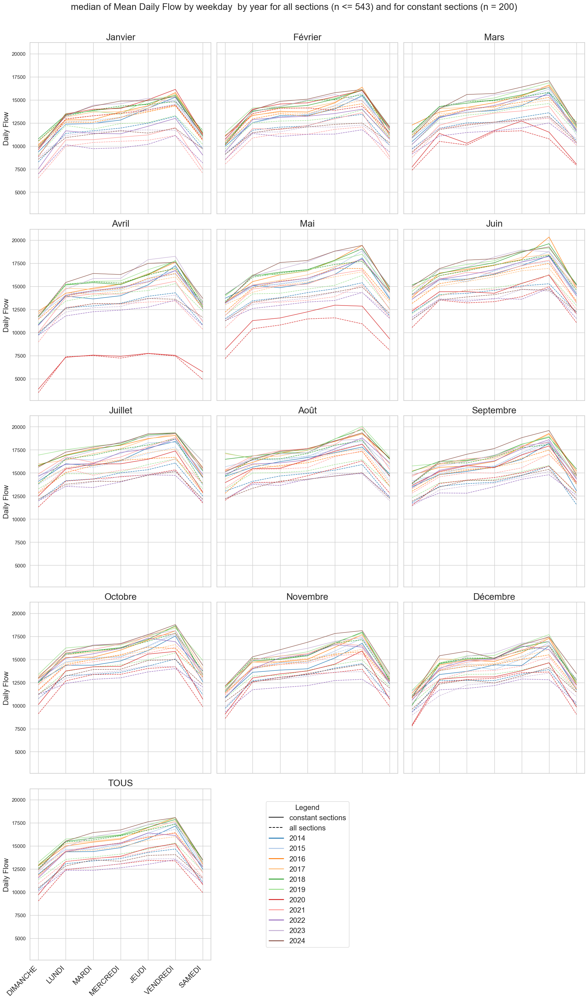

In [151]:
plot_data(fact84_dict, 'fact84', weekday = True, stat = 'median', suffix = 'tot')

Translations

Dimanche - Sunday;

Lundi - Monday;

Mardi - Tuesday;

Mercredi - Wednesday;

Jeudi - Thursday;

Vendredi - Friday;

Samedi - Saturday;

Moyen - Average

Tous - All

In [154]:
def plot_djmm_distribution(fact84_dict, indicator = 'MOYEN', constant_sections = True, suffix = 'normalized', 
    inner_percentile = 25, outer_percentile = 10, cols_per_row = 4, title_begin = ''):

    # indicator can be 'MOYEN' (mean of all week days) or any day of the week

    base = 'constant' if constant_sections else 'all'
    indicator = indicator + '_' + suffix

    year_ref = fact84_dict['year_ref']
    years = sorted(set(fact84_dict[base]['df']['ANNEE']))

    # Pad years to fill the last row completely
    remainder = len(years) % cols_per_row
    if remainder != 0:
        padding = cols_per_row - remainder
        years_padded = years + [None] * padding
    else:
        years_padded = years
        
    n_cols = cols_per_row
    n_rows = int(np.ceil(len(years) / cols_per_row))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows), sharey=True)
    axes = np.array(axes).reshape(n_rows, n_cols)

    for row in range(n_rows):
        row_years = years_padded[row * cols_per_row : (row + 1) * cols_per_row]

        # Build x-axis only for real years, but keep None placeholders for spacing
        x_labels = [(year, month) for year in row_years for month in month_order]
        x_pos    = list(range(len(x_labels)))
    
        means, medians = [], []
        lower_x, upper_x = [], []
        lower_z, upper_z = [], []
    
        for year, month in x_labels:
            if year is None:  # no data for padded years
                for lst in [means, medians, lower_x, upper_x, lower_z, upper_z]:
                    lst.append(np.nan)
                continue
            df = fact84_dict[base]['df']
            data = df[(df['ANNEE'] == year) &
                              (df['MOIS']  == month)][indicator].dropna()
            if len(data) == 0:
                for lst in [means, medians, lower_x, upper_x, lower_z, upper_z]:
                    lst.append(np.nan)
                continue
            means.append(data.mean())
            medians.append(data.median())
            lower_x.append(np.nanpercentile(data, inner_percentile))
            upper_x.append(np.nanpercentile(data, 100 - inner_percentile))
            lower_z.append(np.nanpercentile(data, outer_percentile))
            upper_z.append(np.nanpercentile(data, 100 - outer_percentile))
            
        # Use the first axis of the row and span it across all columns
        for col in range(1, len(row_years)):
            axes[row, col].set_visible(False)
        ax = axes[row, 0]
        ax.set_position([axes[row, 0].get_position().x0,
                         axes[row, 0].get_position().y0,
                         axes[row, -1].get_position().x1 - axes[row, 0].get_position().x0,
                         axes[row, 0].get_position().height])
    
        ax.fill_between(x_pos, lower_z, upper_z, alpha=0.15, color='steelblue', label=f'{outer_percentile}th-{100-outer_percentile}th pct zone')
        ax.fill_between(x_pos, lower_x, upper_x, alpha=0.35, color='steelblue', label=f'{inner_percentile}th-{100-inner_percentile}th pct zone')
        ax.plot(x_pos, means,   color='steelblue', linewidth=2, linestyle='-',  label='Mean')
        ax.plot(x_pos, medians, color='steelblue', linewidth=2, linestyle='--', label='Median')

        ax.set_xlim(x_pos[0], x_pos[-1])
        # x-tick labels: show month, and year only at the first month of each year
        tick_labels = []
        for year, month in x_labels:
            if month == month_order[0]:
                label_year = str(year) if year is not None else ''
                tick_labels.append(f'{month}\n{label_year}')
            else:
                tick_labels.append(str(month))
    
        ax.set_xticks(x_pos)
        ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)
        ylabel = 'Normalized DJMM' if suffix == 'normalized' else ''
        ax.set_ylabel(ylabel, fontsize=11)
        ax.grid(True, alpha=0.3)

    # Shared legend
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower right', fontsize=12,
               bbox_to_anchor=(1.0, 0.0), title='Legend', title_fontsize=12)

    normalized_text = f"- normalized with reference year ({year_ref}) DJMA -" if suffix == 'normalized' else ''
    n = len(df[(df[indicator].notna())&(df['ANNEE'] == year_ref)]['SECTN'].unique())
    n_text = f"(n = {n})" if constant_sections else f"(n <= {n})"
    fig.suptitle(f'{title_begin}Evolution of DJMM {normalized_text} distribution by Month and Year across {base} sections {n_text}', fontsize=20)
    plt.show()

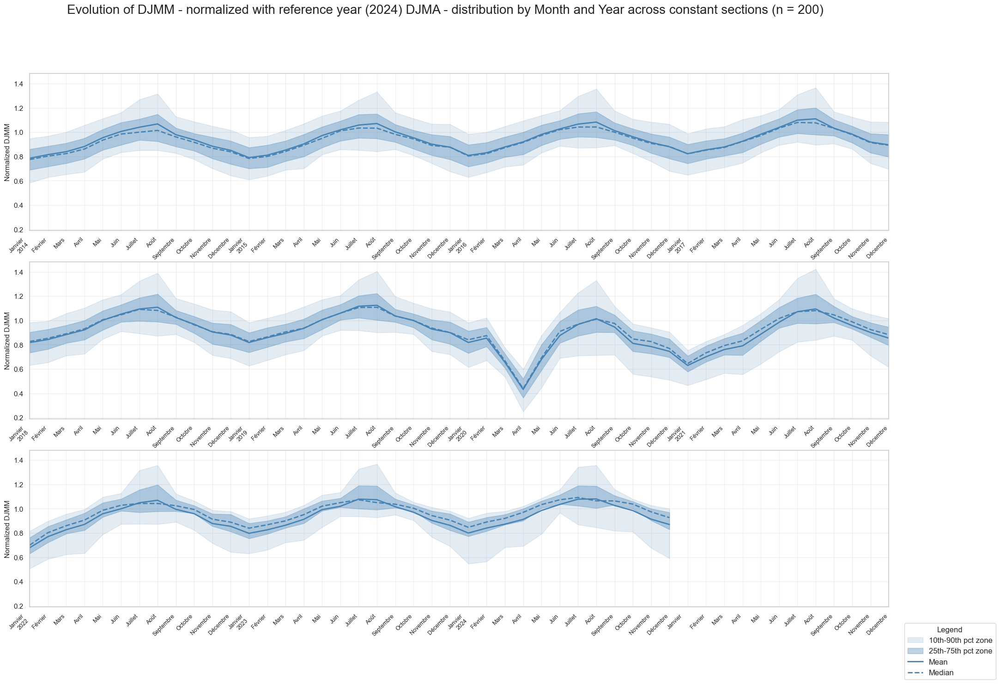

In [156]:
plot_djmm_distribution(fact84_dict, indicator = 'MOYEN')

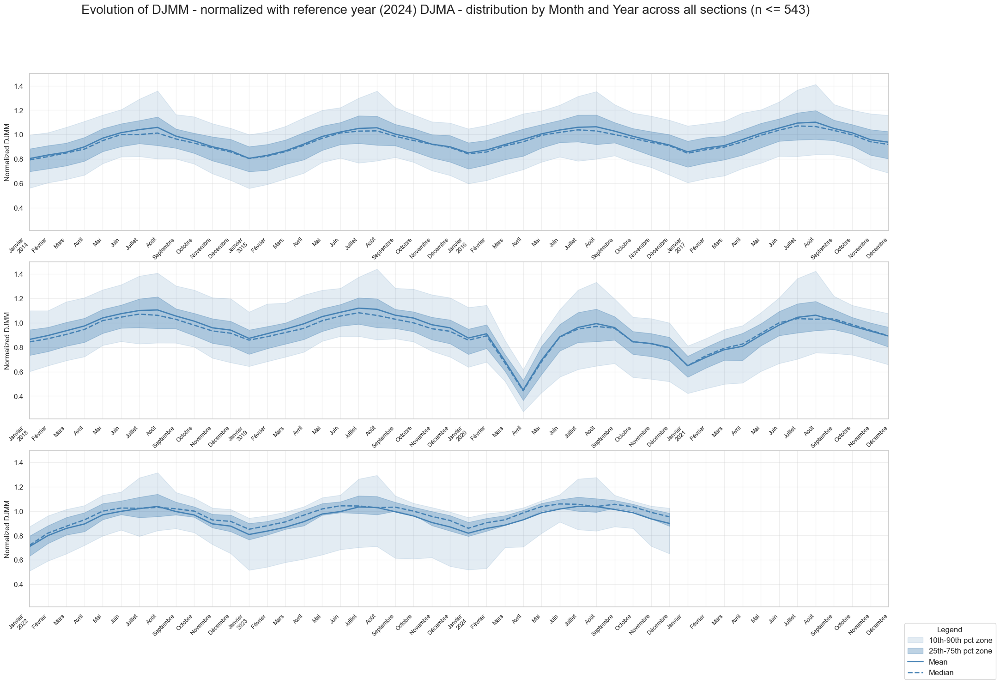

In [158]:
plot_djmm_distribution(fact84_dict, indicator = 'MOYEN', constant_sections = False)

## Section 2.3 Horaire data analysis (hourly flow)

In [161]:
hour_df = create_complete_df('horaire')

In [162]:
verify_lane_equality(hour_df, 'horaire')

############ DIMANCHE ###############
  No value: 73
  Only value for 13: 0
  Only value for 11_12: 55904
  Equal valid values for 11_12 and 13: 24866
  Unequal valid values for 11_12 and 13: 41629

############ SAMEDI ###############
  No value: 73
  Only value for 13: 0
  Only value for 11_12: 55886
  Equal valid values for 11_12 and 13: 25453
  Unequal valid values for 11_12 and 13: 41060

############ OUVRABLE ###############
  No value: 0
  Only value for 13: 0
  Only value for 11_12: 55794
  Equal valid values for 11_12 and 13: 23846
  Unequal valid values for 11_12 and 13: 42832



In [163]:
hour_total = create_total_df(hour_df, 'horaire')

In [164]:
hour_dict = create_data_dict(hour_total, 'horaire', df_djma = histo_all_dict ['histo_merged'] )

Number of common sections per year with data for every period and every of the following indicators: ['DIMANCHE_tot', 'SAMEDI_tot', 'OUVRABLE_tot'] 
2024 : 542
2023 : 447
2022 : 421
2021 : 362
2020 : 341
2019 : 324
2018 : 291
2017 : 270
2016 : 255
2015 : 234
2014 : 200


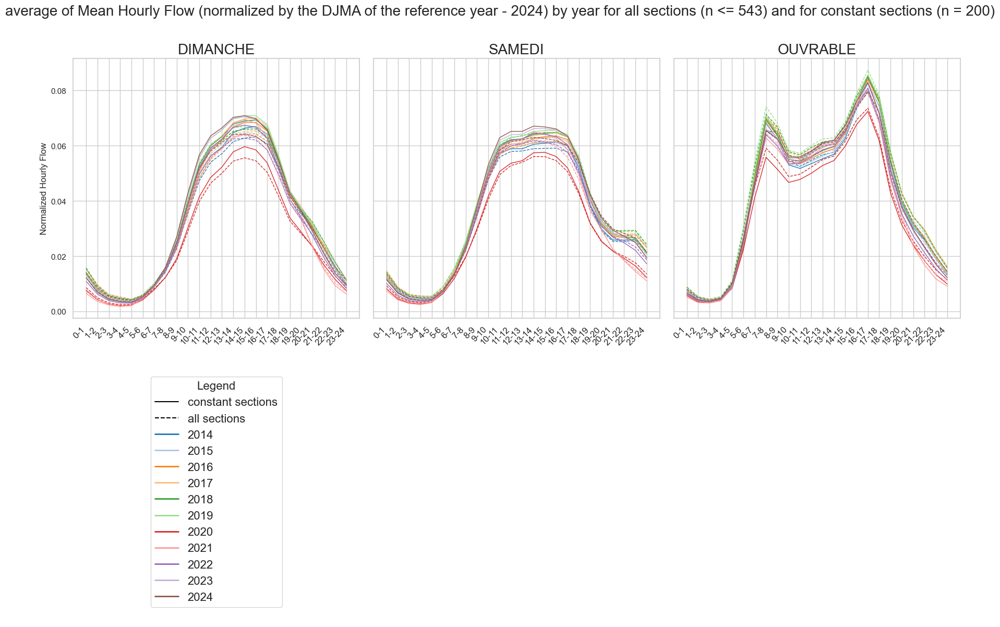

In [169]:
plot_data(hour_dict, 'horaire')

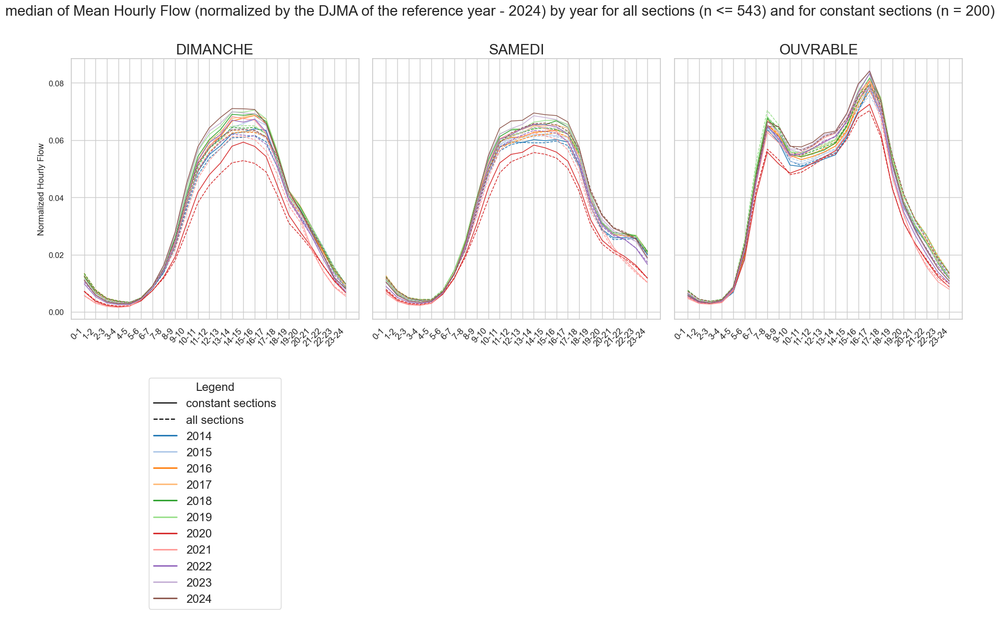

In [171]:
plot_data(hour_dict, 'horaire', stat = 'median')

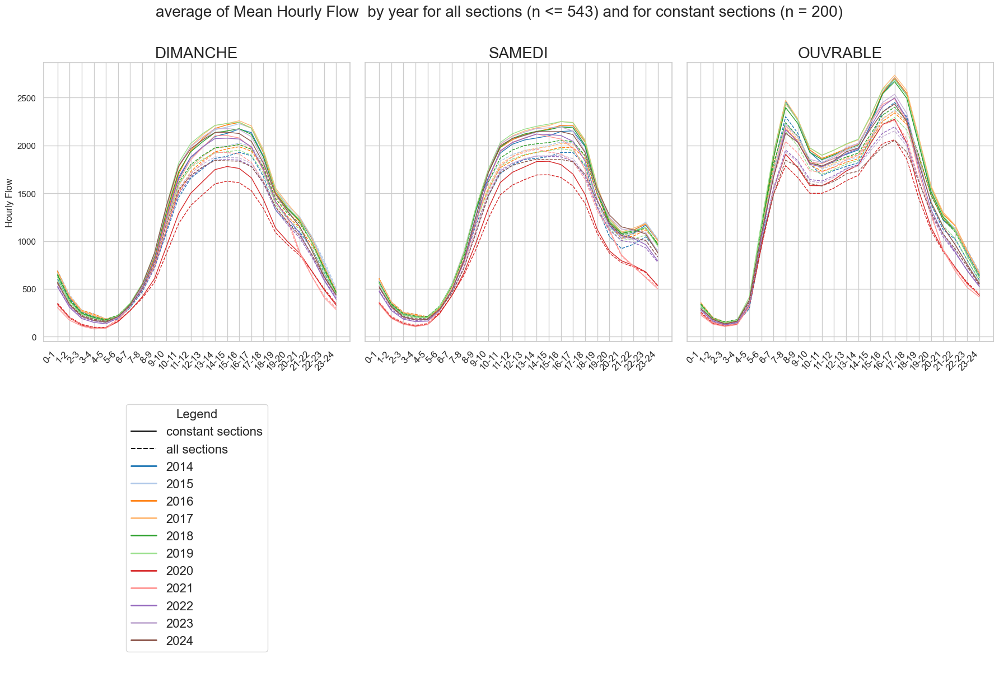

In [173]:
plot_data(hour_dict, 'horaire', suffix = 'tot')

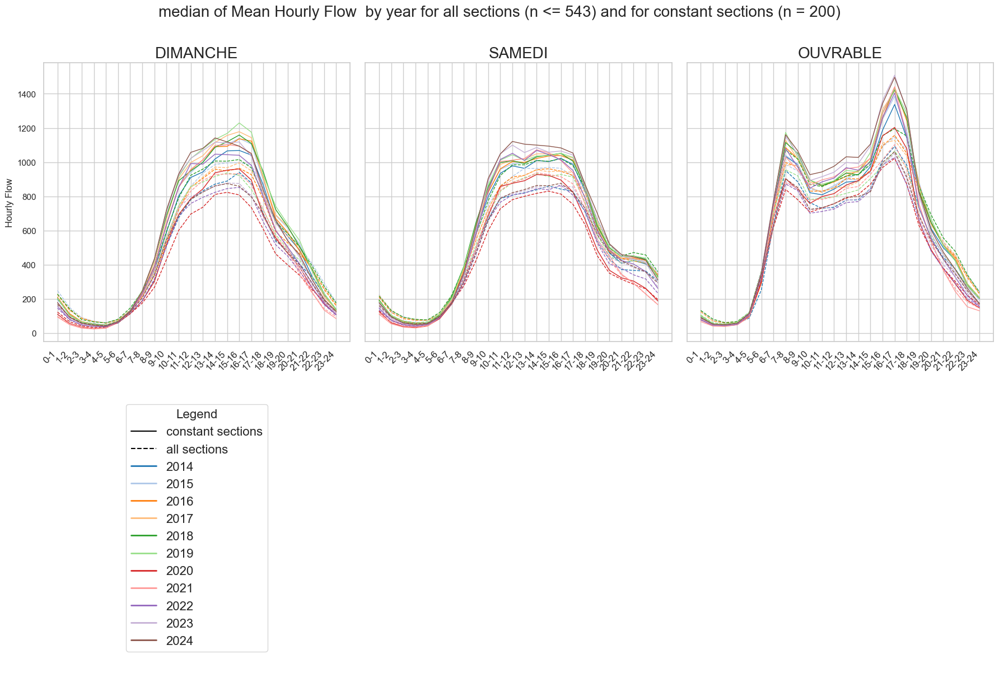

In [175]:
plot_data(hour_dict, 'horaire', suffix = 'tot', stat = 'median')

# Section 3 analysis of sections with the most traffic

The analysis is streamlined for the analysis of:
- sections with most traffic
- sections per region and 
- sections per category

In [253]:
histo_all_dict_outer = histo_all_dict.copy()

In [181]:
def create_dict_df (df, group_var):
    dict_df = {}
    for group in df[group_var].unique():
        dict_df[group] = df[df[group_var] == group]
    return dict_df

In [272]:
def streamline_analysis (dict_sheet, base_data, stat, normalized):
    suffix = 'normalized' if normalized else 'tot'
    constant_sections = False if base_data == 'all' else True
    for sheet, dict_df in dict_sheet.items():
        for name, df in dict_df.items():
            if df.empty:
                continue
            # Annual flow analysis (histo sheet)
            if sheet == 'histo':
                histo_dict, histo_all_dict = create_histo_dict(df, show = False)
                if base_data == 'constant':
                    plot_histo_data (histo_dict = histo_dict, stat = stat, normalized = normalized, title_begin = name)
                elif base_data == 'all': 
                    plot_histo_data (histo_all_dict = histo_all_dict, stat = stat, normalized = normalized, title_begin = name)
                elif base_data == 'both':
                    plot_histo_data (histo_dict = histo_dict, histo_all_dict = histo_all_dict, stat = stat, normalized = normalized, title_begin = name)
            else:
                group_dict = create_data_dict(df, sheet,  histo_all_dict_outer ['histo_merged'], show = False)
                plot_data(group_dict, sheet, base_data= base_data, stat = stat, suffix = suffix, title_begin = name+' - ')
                if sheet == 'fact84':
                    plot_data(group_dict, sheet, base_data= base_data, stat = stat, suffix = suffix, title_begin = name+' - ', weekday = True)
                    plot_djmm_distribution(group_dict, indicator = 'MOYEN',constant_sections = constant_sections, suffix = suffix, title_begin = name + ' - ')

In [251]:
n_top_sectn = 20 # 20 sections with highest average yearly flow
df_histo = histo_dict['DJMA']['df']
top_sectn = df_histo.groupby(['SECTN'], as_index = False)['DJMA_tot'].mean().sort_values(by = 'DJMA_tot', ascending = False)[0:n_top_sectn] ['SECTN']

In [199]:
top_sectn_histo_df = df_histo[df_histo['SECTN'].isin(top_sectn)]
fact84_df = fact84_dict['all']['df']
top_sectn_fact84_df = fact84_df[fact84_df['SECTN'].isin(top_sectn)]
hour_df = hour_dict['all']['df']
top_sectn_hour_df = hour_df[hour_df['SECTN'].isin(top_sectn)]

top_sectn_dict = {'histo': {'top sections':top_sectn_histo_df}, 'fact84': {'top sections':top_sectn_fact84_df}, 'horaire': {'top sections':top_sectn_hour_df}}

In [291]:
# uncoment the line below to show the figures for top sections (with the figures, the file is too big to add on github )
#streamline_analysis (top_sectn_dict, base_data = 'constant', stat = 'average', normalized = True)

# Section 4 Analysis by region

In [266]:
num_sectn_df = histo_data[['SECTN', 'num_sectn__x']].drop_duplicates(subset = 'SECTN')
num_sectn_df.columns = ['SECTN', 'num_sectn_']

gdf = gpd.read_file(r"cir_v_geo_sectn_trafc_locls\cir_v_geo_sectn_trafc_locls.shp") 
sectn_gdf = pd.merge(num_sectn_df, gdf[['num_sectn_', 'geometry']], on = 'num_sectn_', how = 'left')
sectn_gdf = gpd.GeoDataFrame(sectn_gdf, crs=gdf.crs)

gdf_region = gpd.read_file(r"regions\regio_s.shp")
sectn_gdf = sectn_gdf.to_crs(gdf_region.crs)

gdf_region_renamed = gdf_region[['RES_NM_REG', 'geometry']].rename(columns={'RES_NM_REG': 'region'})
gdf_clipped = gpd.overlay(sectn_gdf, gdf_region_renamed, how='intersection', keep_geom_type=True)
df_region = gdf_clipped[['SECTN', 'region']] 

In [268]:
region_dict = {}

for sheet, df in [('histo', histo_total), ('fact84', fact84_total), ('horaire', hour_total)]:
    df_reg = pd.merge(df, df_region, on = 'SECTN', how = 'left')
    region_dict[sheet] = create_dict_df(df_reg, 'region')

In [293]:
# uncoment the line below to show the figures by region (with the figures, the file is too big to add on github )
#streamline_analysis (region_dict, base_data = 'constant', stat = 'average', normalized = True)

# Section 5 analysis by road section category

In [281]:
gdf = gpd.read_file(r"cir_v_geo_sectn_trafc_locls\cir_v_geo_sectn_trafc_locls.shp")
rtss = gpd.read_file(r"ReseauRoutier_RTSS.gpkg")
gdf['num_rts'] = gdf['rtss_fin'].str.replace('-', '', regex=False)
sectn_num_rts = pd.merge(num_sectn_df, gdf[['num_sectn_', 'num_rts']], on = 'num_sectn_', how = 'left')
sectn_category = pd.merge(sectn_num_rts, rtss[['num_rts', 'des_clasf_']], on = 'num_rts', how = 'left')
sectn_category = sectn_category[['SECTN', 'des_clasf_']]
sectn_category.columns = ['SECTN', 'category']
sectn_category = sectn_category[sectn_category['category'].notna()]

In [283]:
category_dict = {}

for sheet, df in [('histo', histo_total), ('fact84', fact84_total), ('horaire', hour_total)]:
    df_cat = pd.merge(df, sectn_category, on = 'SECTN', how = 'left').dropna(subset = 'category')
    category_dict[sheet] = create_dict_df(df_cat, 'category')

In [295]:
# uncoment the line below to show the figures for top sections (with the figures, the file is too big to add on github )
#streamline_analysis (category_dict, base_data = 'constant', stat = 'average', normalized = True)